# HIGSynth: train the UI-element detector (YOLO → Core ML)

**Before you start**
1. Upload `higsynth_yolo.zip` (from your `HIGSynthDataset` folder) to Google Drive, inside a folder named **`HIGSynth`** at the top level of *My Drive*.
2. In Colab: **Runtime → Change runtime type → T4 GPU → Save**.
3. Run the cells **one at a time, top to bottom** (click a cell, press **Shift + Enter**).

Everything the notebook produces (checkpoints, results, the final Core ML model) is saved to *My Drive/HIGSynth*, so nothing is lost if Colab disconnects.

## 1. Install (the session restarts once — that's expected)
After this cell finishes, Colab shows *"Your session crashed"* or restarts. That is intentional: it loads the right library versions. Then continue with step 2.

In [ ]:
!pip install -q "ultralytics>=8.4,<9" "coremltools>=9.0" "numpy<=2.3.5"
# Restart the runtime so the pinned NumPy version is used (Core ML export fails with newer NumPy).
import os; os.kill(os.getpid(), 9)

## 2. Connect Google Drive and unpack the dataset

In [1]:
import os, shutil, zipfile, torch
from google.colab import drive
drive.mount('/content/drive')

DRIVE_DIR = '/content/drive/MyDrive/HIGSynth'
ZIP = f'{DRIVE_DIR}/higsynth_yolo.zip'
DATA = '/content/higsynth_yolo/data.yaml'
RUNS = f'{DRIVE_DIR}/runs'

assert os.path.exists(ZIP), f'Not found: {ZIP}. Upload higsynth_yolo.zip into My Drive/HIGSynth first.'
!assert torch.cuda.is_available(), 'No GPU. Runtime → Change runtime type → T4 GPU, then run again from step 2.'

if not os.path.exists(DATA):
    shutil.copy(ZIP, '/content/higsynth_yolo.zip')            # copying first is much faster than reading from Drive
    zipfile.ZipFile('/content/higsynth_yolo.zip').extractall('/content')
for split in ['train', 'val', 'test']:
    print(split, len(os.listdir(f'/content/higsynth_yolo/images/{split}')), 'images')
print('GPU:', torch.cuda.get_device_name(0))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/bin/bash: -c: line 1: syntax error near unexpected token `('
/bin/bash: -c: line 1: `assert torch.cuda.is_available(), 'No GPU. Runtime → Change runtime type → T4 GPU, then run again from step 2.''
train 2375 images
val 315 images
test 310 images


AssertionError: Torch not compiled with CUDA enabled

## 3. Train (about 1–2 hours)
Keeps the screenshots' tall shape (no squashing) at 1024 px. Training stops early if it stops improving.

Keep this browser tab open. If Colab disconnects, run steps 1–2 again, then run **step 3b** instead of this cell.

In [ ]:
from ultralytics import YOLO

model = YOLO('yolo11s.pt')                 # small, fast model pre-trained on general images
model.train(
    data=DATA,
    imgsz=1024,          # long side in pixels; keeps thin elements (text fields, segmented controls) visible
    epochs=60,
    patience=15,         # stop early if validation stops improving for 15 epochs
    batch=-1,            # pick the largest batch that fits on the GPU
    cache='ram',
    workers=2,
    fliplr=0.0,          # don't mirror screenshots (mirrored text never appears in real apps)
    project=RUNS, name='higsynth', exist_ok=True,
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/higsynth_yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, 

### 3b. Only if Colab disconnected during training: resume

In [2]:
from ultralytics import YOLO
YOLO(f'{RUNS}/higsynth/weights/last.pt').train(resume=True)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=10, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/higsynth_yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, 

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5, 6, 7])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x78a9ab82d320>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,

## 4. Score on the test set
These are screenshots the model never saw during training. Per class:
**precision** = how often a detected box is right, **recall** = how many real elements were found, **mAP50** = overall detection quality (higher is better; 80%+ is good).

In [2]:
import pandas as pd
from ultralytics import YOLO

best = YOLO(f'{RUNS}/higsynth/weights/best.pt')
metrics = best.val(data=DATA, split='test', imgsz=1024, project=RUNS, name='test_eval', exist_ok=True)

rows = []
for i, c in enumerate(metrics.box.ap_class_index):
    p, r, ap50, ap = metrics.box.class_result(i)
    rows.append([best.names[int(c)], round(p * 100), round(r * 100), round(ap50 * 100), round(ap * 100)])
table = pd.DataFrame(rows, columns=['class', 'precision %', 'recall %', 'mAP50 %', 'mAP50-95 %'])
table.to_csv(f'{RUNS}/test_results.csv', index=False)
table

Ultralytics 8.4.177 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11s summary (fused): 100 layers, 9,415,896 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1801.3±664.9 MB/s, size: 161.0 KB)
val: Scanning /content/higsynth_yolo/labels/test... 310 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 310/310 956.7it/s 0.3s
val: New cache created: /content/higsynth_yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 20/20 14.3s/it 4:46
                   all        310       2795      0.998      0.998      0.995      0.994
                navBar        265        265          1          1      0.995      0.995
                tabBar        167        167      0.998          1      0.995      0.995
                button        140        344      0.991      0.996      0.995      0.991
             textField        131        206          1      0.992

,class,precision %,recall %,mAP50 %,mAP50-95 %
0,navBar,100,100,100,99
1,tabBar,100,100,100,99
2,button,99,100,99,99
3,textField,100,99,100,99
4,toggle,100,100,100,99
5,listRow,100,100,100,99
6,segmentedControl,100,100,100,99
7,searchField,100,100,100,99


## 5. Look at predictions on a few test screenshots

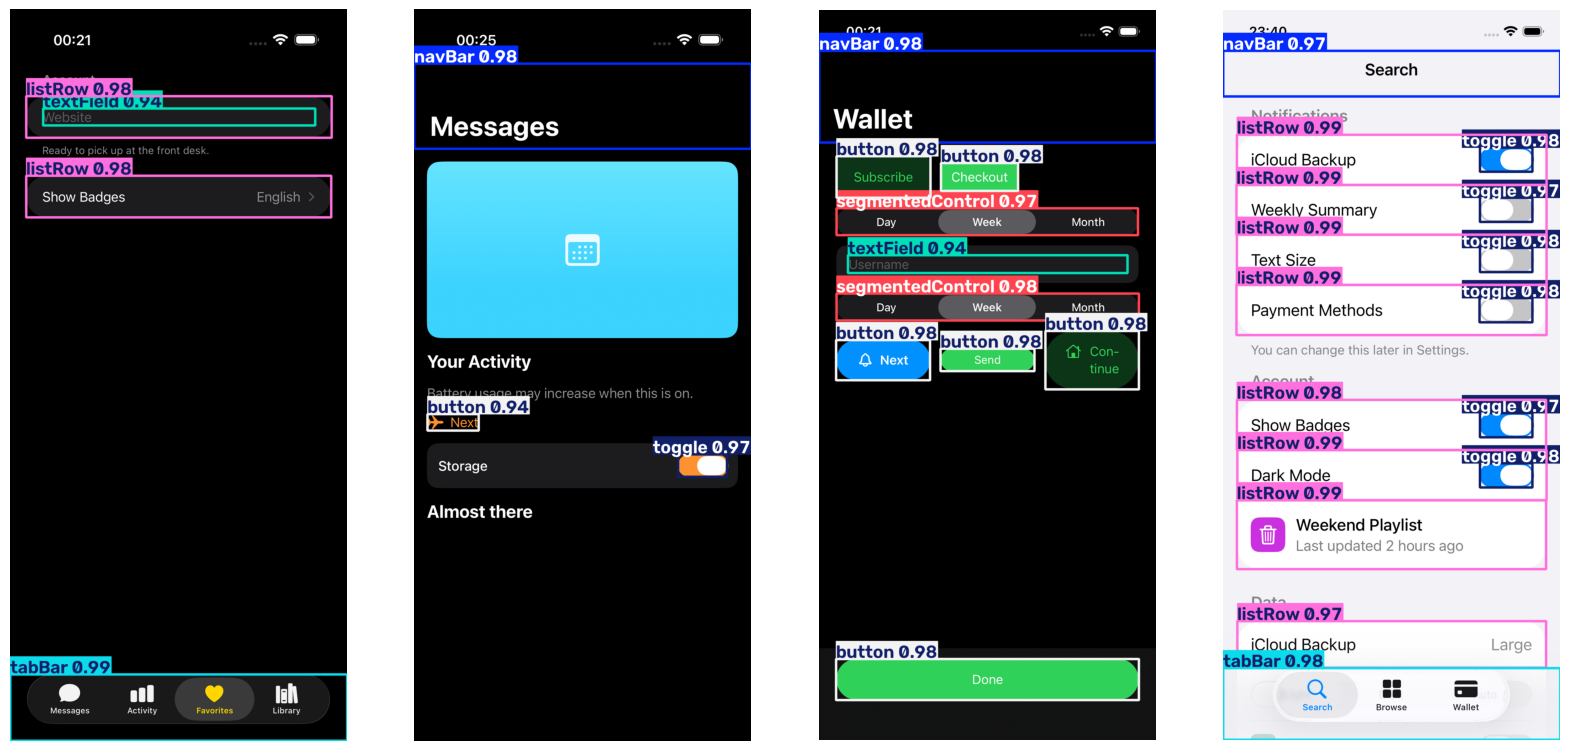

In [3]:
import glob, random
import matplotlib.pyplot as plt

test_images = glob.glob('/content/higsynth_yolo/images/test/*.png')
images = random.sample(test_images, min(4, len(test_images)))
results = best.predict(images, imgsz=1024, conf=0.35, verbose=False)
fig, axes = plt.subplots(1, len(results), figsize=(5 * len(results), 11))
for ax, r in zip(axes, results):
    ax.imshow(r.plot()[..., ::-1]); ax.axis('off')
plt.show()

## 6. Try it on real screenshots (the important test)
Run the cell, click **Choose files**, and pick a few real iPhone screenshots (Settings, Mail, App Store, apps you use).

Saving IMG_4911.PNG to IMG_4911.PNG
Saving IMG_4912.PNG to IMG_4912.PNG
Saving IMG_4913.PNG to IMG_4913.PNG
Saving IMG_4914.PNG to IMG_4914.PNG
Saving IMG_4917.PNG to IMG_4917.PNG
Saving IMG_4918.PNG to IMG_4918.PNG
Saving IMG_4919.PNG to IMG_4919.PNG
Saving IMG_4920.PNG to IMG_4920.PNG
Saving IMG_4921.PNG to IMG_4921.PNG
Saving IMG_4922.PNG to IMG_4922.PNG


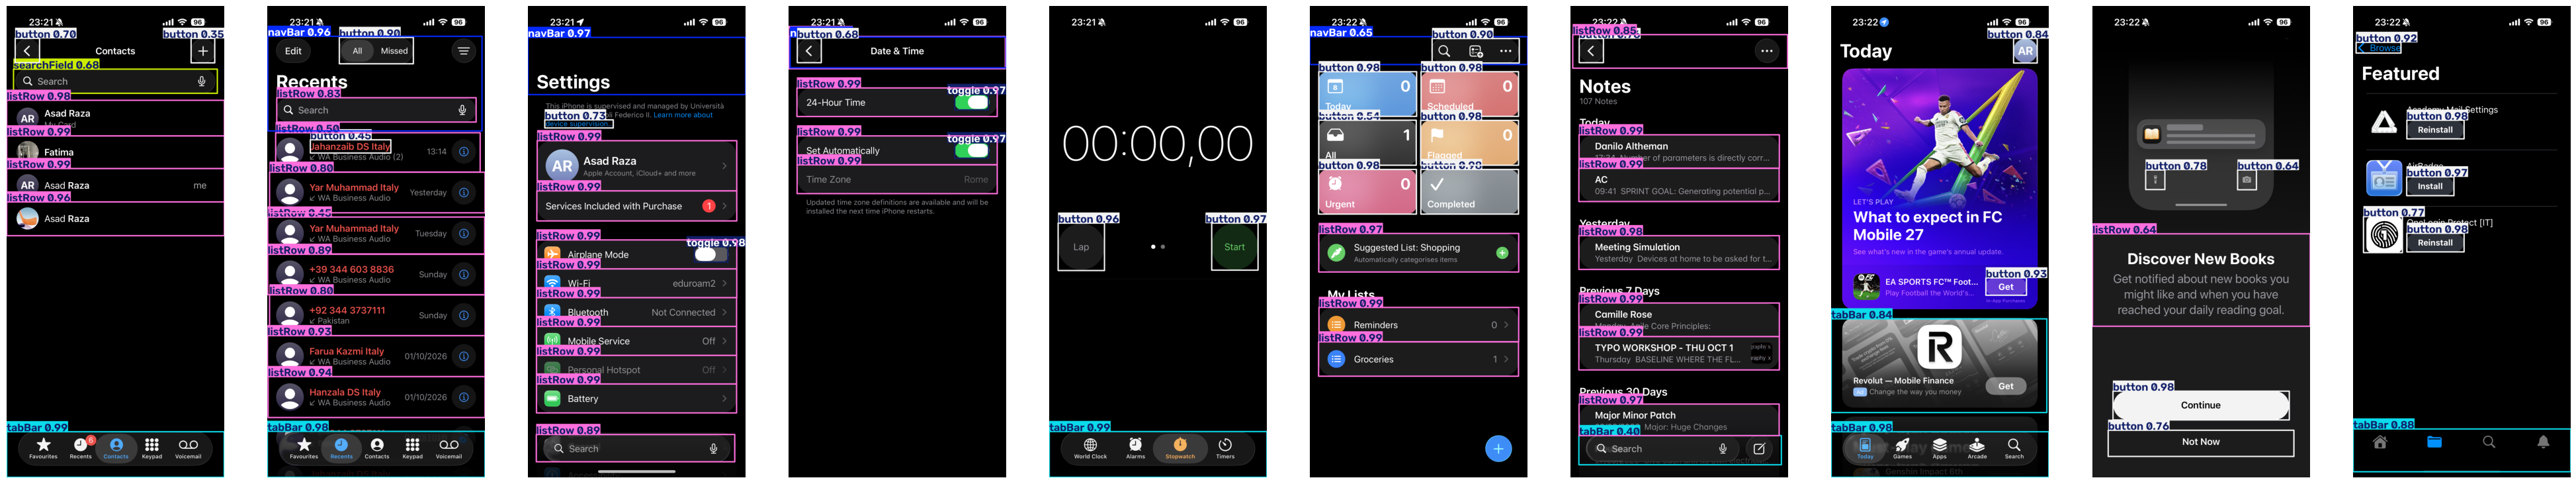

In [5]:
from google.colab import files
import matplotlib.pyplot as plt

uploaded = files.upload()
paths = []
for name, data in uploaded.items():
    path = f'/content/real_{name}'
    open(path, 'wb').write(data)
    paths.append(path)

results = best.predict(paths, imgsz=1024, conf=0.35, verbose=False)
os.makedirs(f'{DRIVE_DIR}/real_predictions', exist_ok=True)
fig, axes = plt.subplots(1, len(results), figsize=(5 * len(results), 11), squeeze=False)
for ax, r in zip(axes[0], results):
    ax.imshow(r.plot()[..., ::-1]); ax.axis('off')
    r.save(filename=f"{DRIVE_DIR}/real_predictions/{os.path.basename(r.path)}")
plt.show()

## 7. Export to Core ML
Creates **`HIGDetector.mlpackage.zip`** in *My Drive/HIGSynth*. Download it, unzip it, and drag `HIGDetector.mlpackage` into Xcode.
The model includes box filtering (NMS), so Apple's Vision framework returns ready-to-use labelled boxes.

In [4]:
mlpackage = best.export(format='coreml', nms=True, imgsz=[1024, 480])   # height x width ≈ iPhone screenshot shape
final = '/content/HIGDetector.mlpackage'
shutil.rmtree(final, ignore_errors=True)
shutil.copytree(mlpackage, final)
shutil.make_archive(f'{DRIVE_DIR}/HIGDetector.mlpackage', 'zip', '/content', 'HIGDetector.mlpackage')
print('Saved:', f'{DRIVE_DIR}/HIGDetector.mlpackage.zip')

Ultralytics 8.4.177 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11s summary (fused): 100 layers, 9,415,896 parameters, 0 gradients, 25.8 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/HIGSynth/runs/higsynth/weights/best.pt' with input shape (1, 3, 1024, 480) BCHW and output shape(s) (1, 12, 10080) (18.3 MB)



CoreML: starting export with coremltools 9.0...


Running MIL default pipeline:   6%|▋         | 6/95 [00:00<00:01, 51.86 passes/s]/usr/local/lib/python3.13/dist-packages/coremltools/converters/mil/mil/passes/defs/preprocess.py:273: UserWarning: Output, '1150', of the source model, has been renamed to 'var_1150' in the Core ML model.
  warnings.warn(msg.format(var.name, new_name))
/usr/local/lib/python3.13/dist-packages/coremltools/converters/mil/mil/passes/defs/preprocess.py:273: UserWarning: Output, '1152', of the source model, has been renamed to 'var_1152' in the Core ML model.
  warnings.warn(msg.format(var.name, new_name))
Running MIL backend_mlprogram pipeline: 100%|██████████| 12/12 [00:00<00:00, 61.90 passes/s]


CoreML: starting pipeline with coremltools 9.0...
CoreML: pipeline success
CoreML: export success ✅ 23.3s, saved as '/content/drive/MyDrive/HIGSynth/runs/higsynth/weights/best.mlpackage' (18.2 MB)

Export complete (24.6s)
Results saved to /content/drive/MyDrive/HIGSynth/runs/higsynth/weights/best.mlpackage
Predict:         yolo predict task=detect model=/content/drive/MyDrive/HIGSynth/runs/higsynth/weights/best.mlpackage imgsz=1024,480 
Validate:        yolo val task=detect model=/content/drive/MyDrive/HIGSynth/runs/higsynth/weights/best.mlpackage imgsz=1024,480 data=/content/higsynth_yolo/data.yaml  WARNING ⚠️ non-PyTorch val requires square images, 'imgsz=[1024, 480]' will not work. Use export 'imgsz=1024' if val is required.
Visualize:       https://netron.app
Saved: /content/drive/MyDrive/HIGSynth/HIGDetector.mlpackage.zip
